# Semana 13 — Invasión Pixel: una GAN que inventa extraterrestres

**Curso:** Inteligencia Artificial — Universidad Nacional Mayor de San Marcos  
**Tema:** Redes generativas adversarias (GAN) y generación de imágenes  
**Tecnologías:** Python, PyTorch, NumPy y Matplotlib  
**Modalidad:** Google Colab (CPU o GPU, sin claves API y sin descargar conjuntos de datos)

## Pregunta gancho

**¿Puede una inteligencia artificial inventar personajes para un videojuego retro sin que alguien dibuje cada personaje?**

Construiremos una pequeña fábrica de extraterrestres de 16 × 16 píxeles. Primero crearemos un catálogo de ejemplo con reglas geométricas. Después entrenaremos una **GAN condicional (cGAN)** con dos redes:

- **Generador (G):** recibe ruido aleatorio y una familia de extraterrestre; dibuja un personaje nuevo.
- **Discriminador (D):** observa el personaje y la familia declarada; detecta tanto dibujos inventados como dibujos del catálogo con una familia equivocada.

La competencia entre ambos permite que G aprenda patrones del catálogo. No utilizaremos modelos preentrenados ni generaremos imágenes con reglas después del entrenamiento: las imágenes del resultado saldrán de la red neuronal.

**Nota de precisión:** cuando digamos *real* nos referimos a las imágenes **originales del catálogo sintético**. No son fotografías ni ilustraciones de personas reales.

## 1. Objetivos de aprendizaje

Al finalizar podrás explicar qué hace cada red de una GAN, para qué sirve un vector latente, cómo se entrenan ambas redes por turnos, qué añade una condición (familia) y por qué la calidad visual y la diversidad son dos cosas diferentes.

**El recorrido del laboratorio es:** crear catálogo → ver ejemplos → construir G y D → entrenar → visualizar evolución → pedir especies nuevas → jugar a distinguirlas → analizar limitaciones.

## 2. Importar bibliotecas y configurar el entorno

Usamos bibliotecas habituales de Colab. No es obligatorio activar GPU porque los dibujos son pequeños y las redes son sencillas.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader

SEMILLA = 13
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DISPOSITIVO.type == "cpu":
    torch.set_num_threads(min(2, torch.get_num_threads()))

NOMBRES = ["Antenas", "Robot", "Medusa"]
COLORES = ["#59efb2", "#ffbf66", "#bb9aff"]
MAPAS = [LinearSegmentedColormap.from_list("alien" + str(i), ["#0a1024", c])
         for i, c in enumerate(COLORES)]

print("Dispositivo:", DISPOSITIVO)
print("Familias disponibles:", ", ".join(NOMBRES))

Dispositivo: cpu
Familias disponibles: Antenas, Robot, Medusa


## 3. Crear el catálogo de entrenamiento

Para no depender de archivos externos, dibujaremos **1 800 extraterrestres diferentes** mediante reglas simples. Estas reglas solo producen el conjunto de entrenamiento. La GAN **no conoce** la función que los dibuja y deberá aprender a partir de sus píxeles.

Las tres familias comparten una estética retro, pero presentan ciertas diferencias: antenas, cuerpo robótico y tentáculos. Cada personaje incorpora variaciones aleatorias en el contorno y los ojos.

In [2]:
def crear_alien(rng, tipo):
    """Devuelve una imagen sintética de 16x16 (0 = fondo; 1 = píxel activo)."""
    imagen = np.zeros((16, 16), dtype=np.float32)

    if tipo == 0:      # Antenas: cabeza redondeada
        anchos = np.array([1, 2, 3, 4, 5, 5, 5, 4, 3, 2])
        inicio = 3
    elif tipo == 1:    # Robot: cuerpo más cuadrado
        anchos = np.array([3, 4, 4, 4, 4, 4, 4, 4, 3, 3])
        inicio = 3
    else:              # Medusa: cuerpo y tentáculos
        anchos = np.array([1, 2, 3, 4, 5, 5, 5, 4, 3, 2])
        inicio = 2

    variaciones = rng.integers(-1, 2, size=len(anchos))
    for fila, ancho in enumerate(anchos):
        ancho_final = int(np.clip(ancho + variaciones[fila], 2, 6))
        y = fila + inicio
        imagen[y, 8 - ancho_final:8 + ancho_final] = 1

    if tipo == 0:
        x = int(rng.integers(4, 7))
        imagen[1:4, x] = 1
        imagen[1:4, 15 - x] = 1
        y, ojo = int(rng.choice([6, 7, 8])), int(rng.choice([5, 6]))
        imagen[y, ojo] = imagen[y, 15 - ojo] = 0
        if rng.random() < 0.5:
            imagen[10, 7:9] = 0
        imagen[13:15, 5] = imagen[13:15, 10] = 1

    elif tipo == 1:
        y, ojo = int(rng.choice([6, 7])), int(rng.choice([5, 6]))
        imagen[y, ojo] = imagen[y, 15 - ojo] = 0
        imagen[10, 5:11] = 0
        imagen[2, 7:9] = 1
        imagen[13:15, 5:7] = imagen[13:15, 9:11] = 1

    else:
        y, ojo = int(rng.choice([5, 6])), int(rng.choice([5, 6]))
        imagen[y, ojo] = imagen[y, 15 - ojo] = 0
        imagen[10:15, 5] = imagen[10:15, 10] = 1
        if rng.random() < 0.7:
            imagen[11:15, 7:9] = 1
        if rng.random() < 0.7:
            imagen[11:15, 3] = imagen[11:15, 12] = 1

    if tipo != 2 and rng.random() < 0.8:
        y = int(rng.choice([9, 10]))
        imagen[y, 2:4] = imagen[y, 12:14] = 1

    # Pequeñas variaciones simétricas de textura.
    for _ in range(int(rng.integers(0, 3))):
        y, x = int(rng.integers(4, 12)), int(rng.integers(4, 8))
        imagen[y, x] = 1 - imagen[y, x]
        imagen[y, 15 - x] = imagen[y, x]

    return imagen

rng = np.random.default_rng(SEMILLA)
ETIQUETAS = np.arange(1800, dtype=np.int64) % 3
CATALOGO = np.stack([crear_alien(rng, int(tipo)) for tipo in ETIQUETAS])

print("Forma del catálogo:", CATALOGO.shape)
print("Ejemplos por familia:", {NOMBRES[i]: int((ETIQUETAS == i).sum()) for i in range(3)})

Forma del catálogo: (1800, 16, 16)
Ejemplos por familia: {'Antenas': 600, 'Robot': 600, 'Medusa': 600}


## 4. Visualizar nuestros extraterrestres originales

El color es solo una **paleta de visualización**: el modelo aprenderá imágenes de un canal (intensidades), no imágenes RGB. Esta decisión reduce código, memoria y tiempo de entrenamiento.

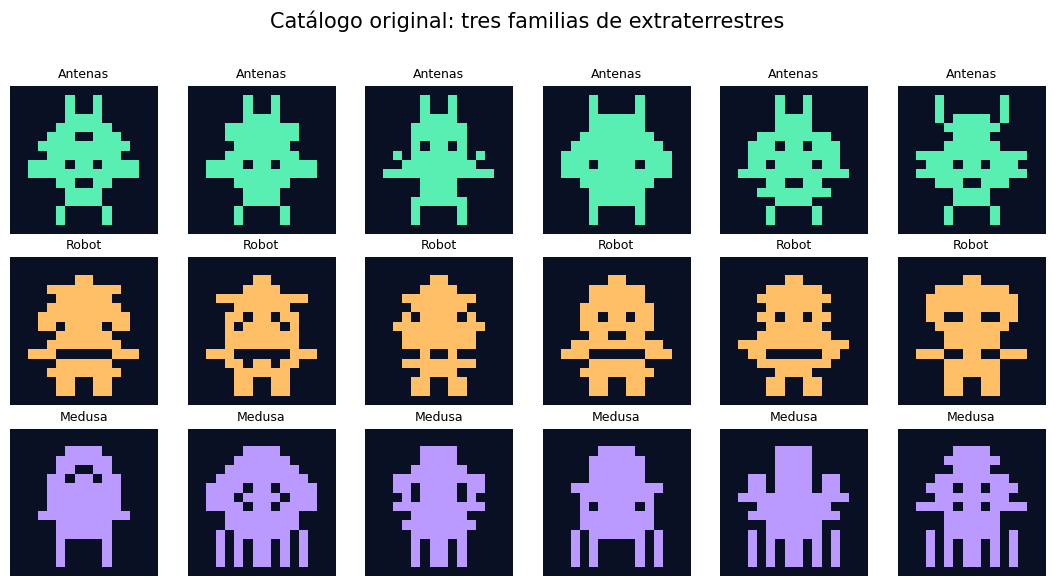

In [3]:
def mostrar_galeria(imagenes, clases, titulo, columnas=6, pixelar=False):
    """Dibuja una galería usando paletas distintas según la familia."""
    imagenes = np.asarray(imagenes)
    clases = np.asarray(clases, dtype=int)
    filas = int(np.ceil(len(imagenes) / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(columnas * 1.8, filas * 1.9))
    axes = np.asarray(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i >= len(imagenes):
            continue
        img = np.asarray(imagenes[i]).reshape(16, 16)
        if pixelar:
            img = (img > 0.5).astype(float)
        ax.imshow(img, vmin=0, vmax=1, cmap=MAPAS[clases[i]], interpolation="nearest")
        ax.set_title(NOMBRES[clases[i]], fontsize=9)
    fig.suptitle(titulo, fontsize=15, y=1.02)
    fig.tight_layout()
    plt.show()

indices = np.concatenate([np.where(ETIQUETAS == c)[0][:6] for c in range(3)])
mostrar_galeria(CATALOGO[indices], ETIQUETAS[indices],
                "Catálogo original: tres familias de extraterrestres")

## 5. ¿Cómo funciona una GAN condicional?

| Parte | Explicación fácil | Entrada | Salida |
|---|---|---|---|
| **Generador** | El dibujante | Ruido `z` + familia elegida | Una imagen inventada |
| **Discriminador** | El detective | Imagen + familia declarada | Una puntuación de autenticidad y coherencia |
| **Condición** | La instrucción del cliente | Antenas, Robot o Medusa | Controla qué tipo se solicita |

**Concepto clave:** el generador transforma un vector aleatorio de 32 números en 256 valores, correspondientes a los píxeles de una imagen de 16 × 16. El discriminador no recibe la respuesta correcta como regla: la aprende de los ejemplos.

La arquitectura es una versión pequeña de una **cGAN**, no una DCGAN convolucional. Se eligieron capas densas para simplificar la explicación y ejecutar el ejemplo rápidamente. (Goodfellow et al., 2014; Mirza & Osindero, 2014).

In [4]:
DIM_RUIDO = 32
N_CLASES = 3

# Convierte números 0, 1, 2 a vectores [1,0,0], [0,1,0], [0,0,1].
def codificar_clase(clases):
    return F.one_hot(clases.long(), num_classes=N_CLASES).float()

# G: ruido + tipo de alien => 256 píxeles.
generador = nn.Sequential(
    nn.Linear(DIM_RUIDO + N_CLASES, 128), nn.ReLU(),
    nn.Linear(128, 256), nn.ReLU(),
    nn.Linear(256, 16 * 16), nn.Tanh()
).to(DISPOSITIVO)

# D: 256 píxeles + tipo de alien => una puntuación de realismo.
discriminador = nn.Sequential(
    nn.Linear(16 * 16 + N_CLASES, 128), nn.LeakyReLU(0.2),
    nn.Linear(128, 64), nn.LeakyReLU(0.2),
    nn.Linear(64, 1)
).to(DISPOSITIVO)

print("Parámetros de G:", sum(p.numel() for p in generador.parameters()))
print("Parámetros de D:", sum(p.numel() for p in discriminador.parameters()))

Parámetros de G: 103424
Parámetros de D: 41601


## 6. Entrenamiento: el dibujante contra el detective

Cada ronda contiene dos pasos: primero **D** aprende con tres tipos de ejemplos —un dibujo de catálogo bien etiquetado, uno de G y uno de catálogo con la **familia equivocada**—; luego **G** intenta producir una imagen que D acepte como auténtica y que corresponda a la familia pedida. Este pequeño truco evita que D ignore completamente las etiquetas.

Usaremos la función `BCEWithLogitsLoss`, el optimizador Adam y *label smoothing* de 0.9 para las muestras del catálogo. Las pérdidas pueden subir y bajar porque ambas redes cambian simultáneamente: **no se interpretan como un indicador único de calidad**.

El número de épocas se puede reducir a 40 para una demostración más corta, pero la calidad puede ser menor. Los resultados variarán dependiendo de la semilla y del entorno.

In [5]:
# Los píxeles pasan de [0, 1] a [-1, 1] para combinar con Tanh.
x_entrenamiento = torch.tensor(CATALOGO[:, None] * 2 - 1, dtype=torch.float32)
y_entrenamiento = torch.tensor(ETIQUETAS, dtype=torch.long)
loader = DataLoader(TensorDataset(x_entrenamiento, y_entrenamiento),
                    batch_size=128, shuffle=True, drop_last=True)

criterio = nn.BCEWithLogitsLoss()
optimizador_d = torch.optim.Adam(discriminador.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizador_g = torch.optim.Adam(generador.parameters(), lr=0.0002, betas=(0.5, 0.999))

EPOCAS = 100
PERDIDAS_G, PERDIDAS_D = [], []
FOTOS_EVOLUCION = {}
ruido_fijo = torch.randn(18, DIM_RUIDO, device=DISPOSITIVO)
clases_fijas = torch.tensor([i // 6 for i in range(18)], device=DISPOSITIVO)

for epoca in range(1, EPOCAS + 1):
    suma_g, suma_d = 0.0, 0.0
    for reales, clases in loader:
        reales, clases = reales.to(DISPOSITIVO), clases.to(DISPOSITIVO)
        n = reales.size(0)
        pixeles = reales.reshape(n, -1)
        condicion = codificar_clase(clases)

        # PASO 1: entrenar al detective con imágenes originales y falsas.
        ruido = torch.randn(n, DIM_RUIDO, device=DISPOSITIVO)
        falsos = generador(torch.cat([ruido, condicion], dim=1))
        optimizador_d.zero_grad()
        puntuacion_real = discriminador(torch.cat([pixeles, condicion], dim=1))
        puntuacion_falsa = discriminador(torch.cat([falsos.detach(), condicion], dim=1))
        condicion_incorrecta = codificar_clase((clases + 1) % N_CLASES)
        puntuacion_incorrecta = discriminador(torch.cat([pixeles, condicion_incorrecta], dim=1))
        perdida_d = (criterio(puntuacion_real, torch.full_like(puntuacion_real, 0.9))
                     + 0.5 * criterio(puntuacion_falsa, torch.zeros_like(puntuacion_falsa))
                     + 0.5 * criterio(puntuacion_incorrecta, torch.zeros_like(puntuacion_incorrecta)))
        perdida_d.backward()
        optimizador_d.step()

        # PASO 2: entrenar al dibujante para intentar engañar al detective.
        ruido = torch.randn(n, DIM_RUIDO, device=DISPOSITIVO)
        nuevos = generador(torch.cat([ruido, condicion], dim=1))
        optimizador_g.zero_grad()
        juicio = discriminador(torch.cat([nuevos, condicion], dim=1))
        perdida_g = criterio(juicio, torch.ones_like(juicio))
        perdida_g.backward()
        optimizador_g.step()

        suma_d += perdida_d.item()
        suma_g += perdida_g.item()

    PERDIDAS_D.append(suma_d / len(loader))
    PERDIDAS_G.append(suma_g / len(loader))

    if epoca in [1, 20, 40, 70, EPOCAS]:
        with torch.no_grad():
            generadas = generador(torch.cat([ruido_fijo, codificar_clase(clases_fijas)], dim=1))
            FOTOS_EVOLUCION[epoca] = ((generadas.reshape(-1, 16, 16) + 1) / 2).cpu().numpy()
        print(f"Época {epoca:>3}/{EPOCAS} | pérdida D: {PERDIDAS_D[-1]:.3f} | pérdida G: {PERDIDAS_G[-1]:.3f}")

Época   1/100 | pérdida D: 1.365 | pérdida G: 0.683
Época  20/100 | pérdida D: 1.041 | pérdida G: 1.674
Época  40/100 | pérdida D: 0.651 | pérdida G: 2.346
Época  70/100 | pérdida D: 0.645 | pérdida G: 2.325
Época 100/100 | pérdida D: 0.701 | pérdida G: 1.656


## 7. Ver cómo aprende la red neuronal

Usamos **el mismo ruido y las mismas familias** para comparar imágenes en diferentes épocas. Al principio G produce patrones sin estructura; con el entrenamiento suelen aparecer formas y rasgos más parecidos a los del catálogo. Una GAN también puede fallar, y esa variación forma parte del aprendizaje.

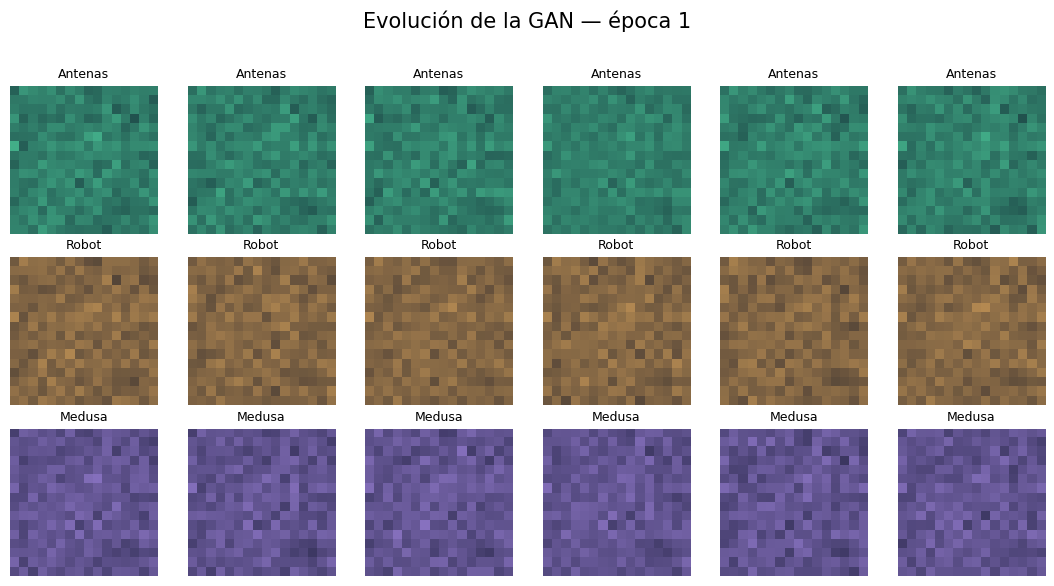

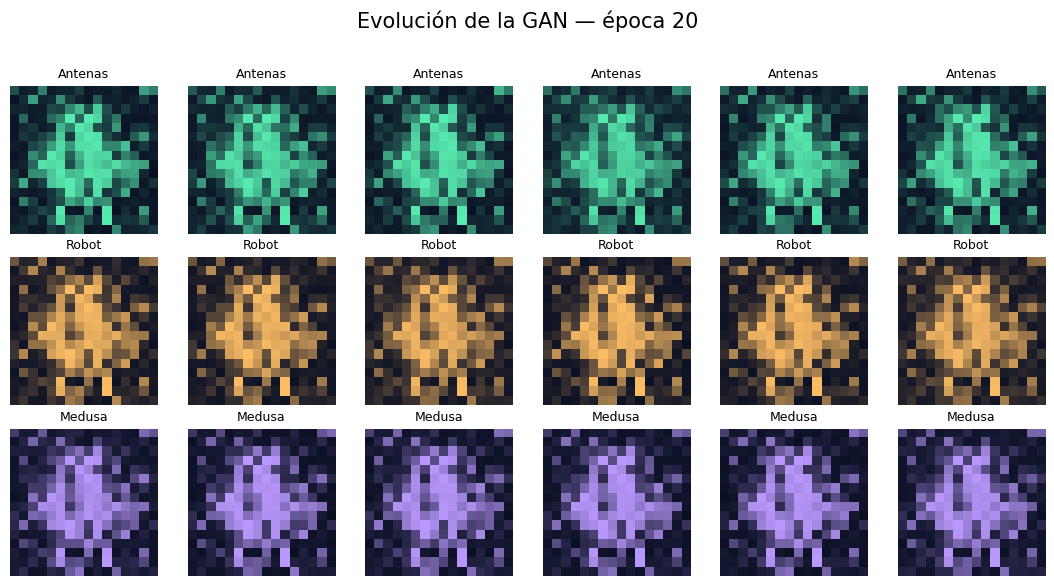

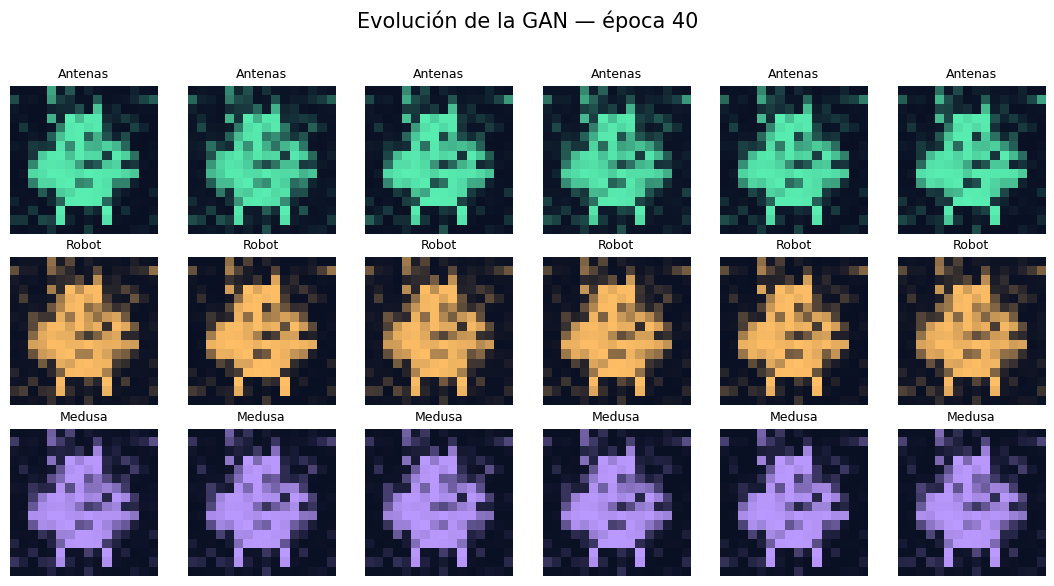

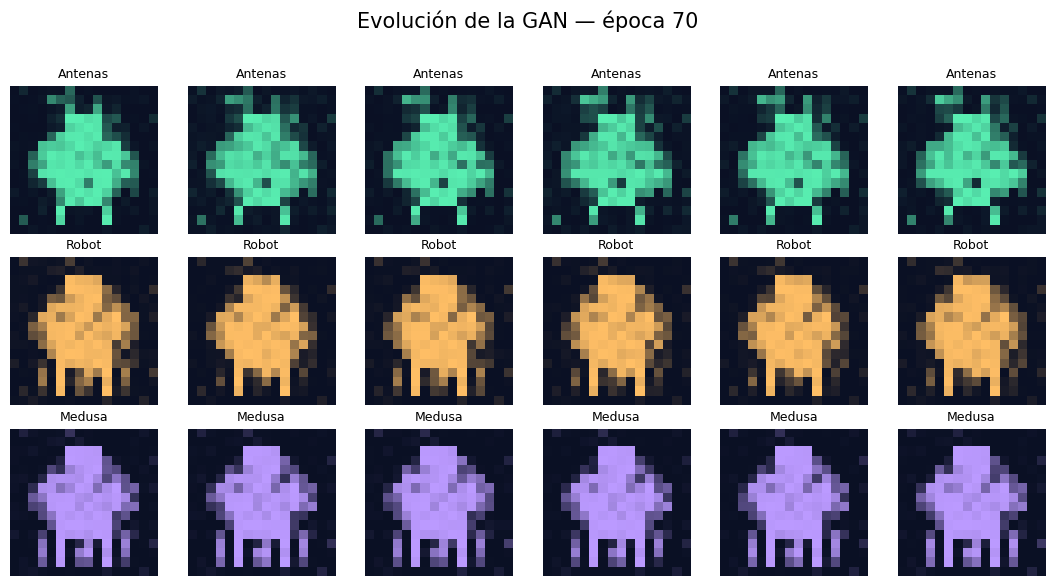

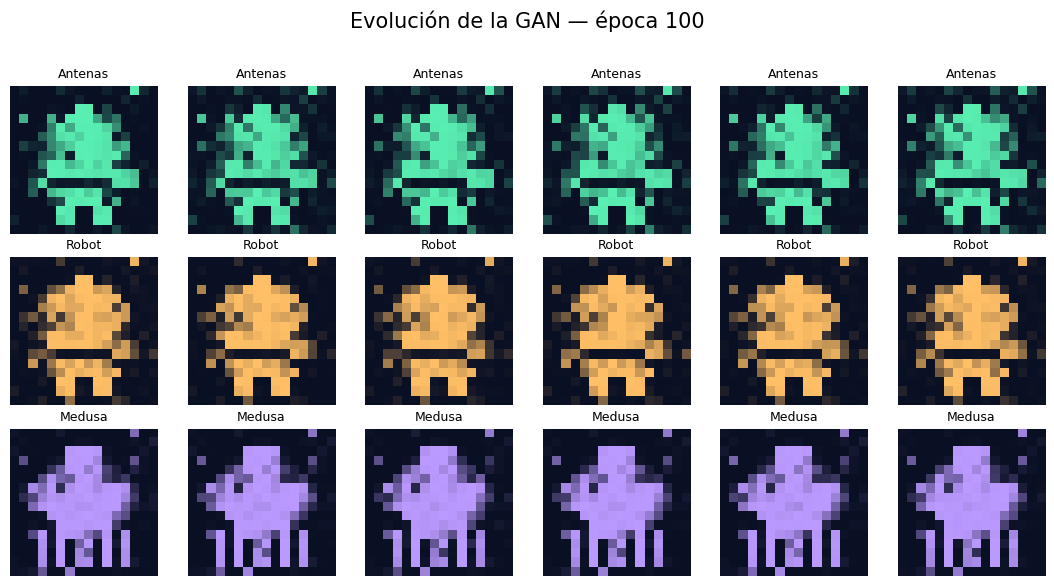

In [6]:
for epoca, imagenes in FOTOS_EVOLUCION.items():
    mostrar_galeria(imagenes, clases_fijas.cpu().numpy(),
                    f"Evolución de la GAN — época {epoca}", columnas=6)

## 8. Revisar las pérdidas del generador y del discriminador

No buscamos necesariamente que ambas curvas bajen sin parar. G y D compiten y sus dificultades cambian durante el entrenamiento. Complementa el gráfico con las galerías anteriores.

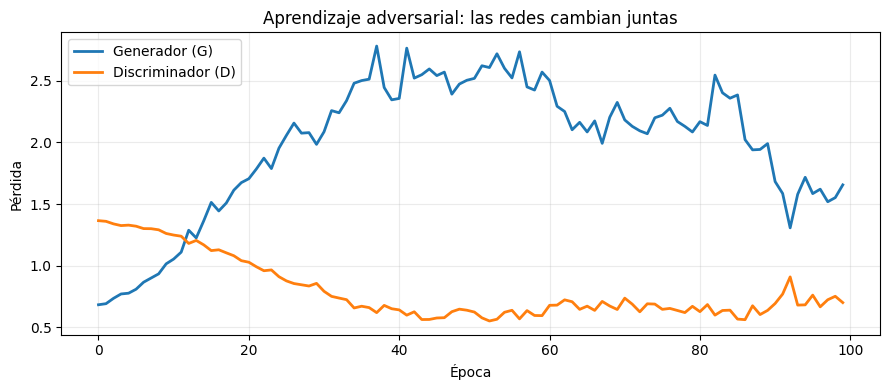

In [7]:
plt.figure(figsize=(9, 4))
plt.plot(PERDIDAS_G, label="Generador (G)", linewidth=2)
plt.plot(PERDIDAS_D, label="Discriminador (D)", linewidth=2)
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Aprendizaje adversarial: las redes cambian juntas")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Taller interactivo: pide una especie

Cambia `FAMILIA_ELEGIDA` por `"Antenas"`, `"Robot"` o `"Medusa"`. El ruido hace que no siempre aparezca exactamente el mismo personaje.

**Importante:** al generar no se ejecuta `crear_alien`: se utiliza exclusivamente el modelo entrenado.

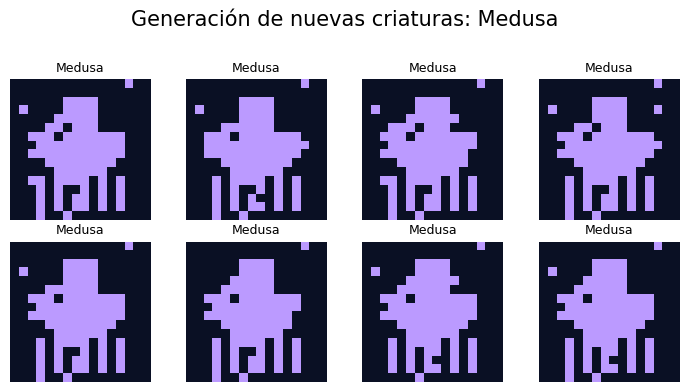

In [8]:
def generar_alienes(tipo, cantidad=8, semilla=2026):
    if tipo not in NOMBRES:
        raise ValueError("Elige una familia de: " + ", ".join(NOMBRES))
    rng_local = torch.Generator(device=DISPOSITIVO).manual_seed(int(semilla))
    clase = NOMBRES.index(tipo)
    tipos = torch.full((cantidad,), clase, dtype=torch.long, device=DISPOSITIVO)
    z = torch.randn(cantidad, DIM_RUIDO, generator=rng_local, device=DISPOSITIVO)
    generador.eval()
    with torch.no_grad():
        imagenes = generador(torch.cat([z, codificar_clase(tipos)], dim=1))
        imagenes = ((imagenes.reshape(-1, 16, 16) + 1) / 2).cpu().numpy()
    generador.train()
    return imagenes, np.full(cantidad, clase)

FAMILIA_ELEGIDA = "Medusa"  # Modifica este texto y ejecuta de nuevo.
mis_alienes, mis_tipos = generar_alienes(FAMILIA_ELEGIDA, cantidad=8, semilla=2026)
mostrar_galeria(mis_alienes, mis_tipos,
                "Generación de nuevas criaturas: " + FAMILIA_ELEGIDA,
                columnas=4, pixelar=True)

## 10. Bonus: modificar el «ADN digital» de un extraterrestre

El vector `z` es como una ficha de características **no interpretables directamente**. Vamos a interpolar entre dos vectores para ver qué ocurre al movernos gradualmente por el **espacio latente**. Esto no equivale a editar genes reales ni permite controlar un rasgo concreto; es una exploración visual.

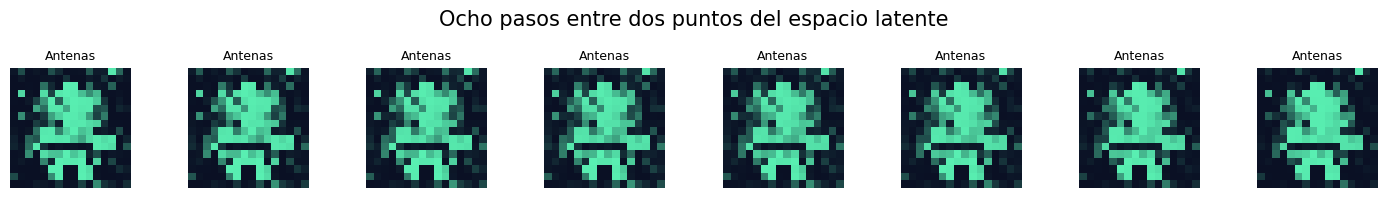

In [9]:
tipo_dna = 0  # 0 = Antenas, 1 = Robot, 2 = Medusa
z_inicio = torch.randn(1, DIM_RUIDO, device=DISPOSITIVO)
z_final = torch.randn(1, DIM_RUIDO, device=DISPOSITIVO)
mezclas = []
with torch.no_grad():
    for t in np.linspace(0, 1, 8):
        z = (1 - float(t)) * z_inicio + float(t) * z_final
        clase = torch.tensor([tipo_dna], device=DISPOSITIVO)
        imagen = generador(torch.cat([z, codificar_clase(clase)], dim=1))
        mezclas.append(((imagen.reshape(16, 16) + 1) / 2).cpu().numpy())
mostrar_galeria(mezclas, [tipo_dna] * 8,
                "Ocho pasos entre dos puntos del espacio latente", columnas=8)

## 11. Juego de clase: ¿catálogo original o GAN?

El docente puede proyectar ocho extraterrestres. Cuatro proceden del catálogo programado originalmente y cuatro de la red entrenada. Anota para cada número **C** (catálogo) o **G** (GAN). No mires la respuesta hasta terminar.

**Aclaración:** este juego compara dos mecanismos de síntesis artificial; no mide si una imagen es una fotografía auténtica.

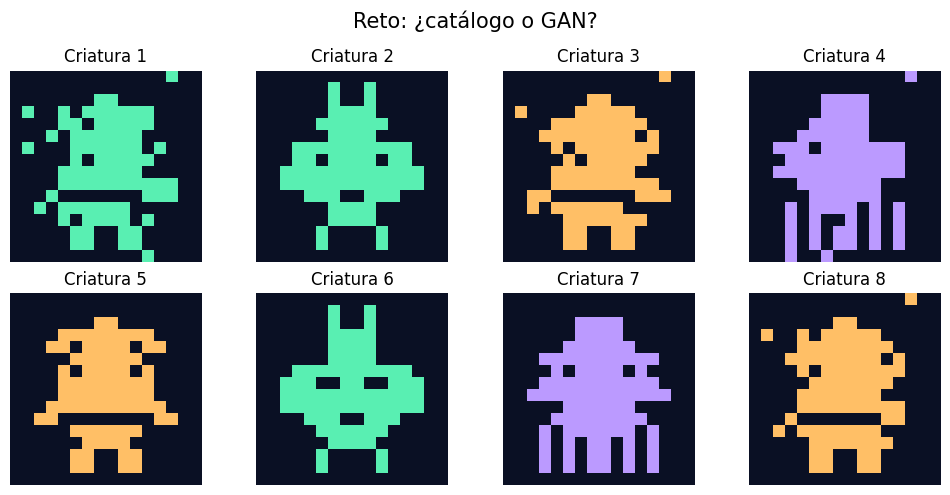

Anota tus ocho respuestas (C o G) antes de ejecutar la siguiente celda.


In [10]:
rng_juego = np.random.default_rng(54)
indices_originales = rng_juego.choice(len(CATALOGO), size=4, replace=False)
originales = CATALOGO[indices_originales]
clases_originales = ETIQUETAS[indices_originales]

clases_sinteticas = rng_juego.integers(0, 3, size=4)
ruido_juego = torch.randn(4, DIM_RUIDO, device=DISPOSITIVO)
with torch.no_grad():
    clases_gpu = torch.tensor(clases_sinteticas, device=DISPOSITIVO)
    inventados = generador(torch.cat([ruido_juego, codificar_clase(clases_gpu)], 1))
    inventados = ((inventados.reshape(-1, 16, 16) + 1) / 2).cpu().numpy()

imagenes_juego = np.concatenate([originales, inventados])
clases_juego = np.concatenate([clases_originales, clases_sinteticas])
respuestas_juego = np.array(["C"] * 4 + ["G"] * 4)
orden = rng_juego.permutation(8)
imagenes_juego, clases_juego = imagenes_juego[orden], clases_juego[orden]
respuestas_juego = respuestas_juego[orden]

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow((imagenes_juego[i] > 0.5), cmap=MAPAS[int(clases_juego[i])],
              vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"Criatura {i+1}", fontsize=12)
    ax.axis("off")
plt.suptitle("Reto: ¿catálogo o GAN?", fontsize=15)
plt.tight_layout()
plt.show()
print("Anota tus ocho respuestas (C o G) antes de ejecutar la siguiente celda.")

In [11]:
print("RESPUESTAS DEL JUEGO")
for i, letra in enumerate(respuestas_juego, start=1):
    print(f"Criatura {i}: {'Catálogo original' if letra == 'C' else 'Generada por GAN'}")

RESPUESTAS DEL JUEGO
Criatura 1: Generada por GAN
Criatura 2: Catálogo original
Criatura 3: Generada por GAN
Criatura 4: Generada por GAN
Criatura 5: Catálogo original
Criatura 6: Catálogo original
Criatura 7: Catálogo original
Criatura 8: Generada por GAN


## 12. Evaluación sencilla: ¿está repitiendo el mismo extraterrestre?

Las GAN pueden presentar *mode collapse*: muchos vectores de ruido acaban dando imágenes muy similares. Comprobaremos dos señales simples sobre 120 muestras: cuántos sprites binarizados son distintos y cuántos son **copias exactas** de algún dibujo de entrenamiento.

Estas medidas **no equivalen** a FID, SSIM ni a una prueba completa de calidad o creatividad. Dos dibujos distintos pueden parecerse mucho, y uno no idéntico todavía puede ser una variación trivial.

In [12]:
muestras_prueba = []
for clase in NOMBRES:
    fotos, _ = generar_alienes(clase, cantidad=40, semilla=100 + NOMBRES.index(clase))
    muestras_prueba.extend(fotos)

muestras_prueba = np.asarray(muestras_prueba)
bitmaps = (muestras_prueba > 0.5).astype(np.uint8)
claves_generadas = {img.tobytes() for img in bitmaps}
claves_catalogo = {img.astype(np.uint8).tobytes() for img in CATALOGO}

unicos = len(claves_generadas)
copias_exactas = sum(img.tobytes() in claves_catalogo for img in bitmaps)
print(f"Sprites generados: {len(bitmaps)}")
print(f"Patrones binarios diferentes: {unicos} de {len(bitmaps)}")
print(f"Coincidencias exactas con el catálogo: {copias_exactas}")
print("Interpretación: la diversidad y la ausencia de copias exactas no garantizan calidad visual.")

Sprites generados: 120
Patrones binarios diferentes: 91 de 120
Coincidencias exactas con el catálogo: 0
Interpretación: la diversidad y la ausencia de copias exactas no garantizan calidad visual.


## 13. Guardar y descargar tus extraterrestres

Exportaremos una galería PNG y los pesos del generador. El archivo de pesos se puede usar para continuar experimentando con la misma arquitectura, mientras que el PNG sirve para mostrar el resultado durante la exposición.

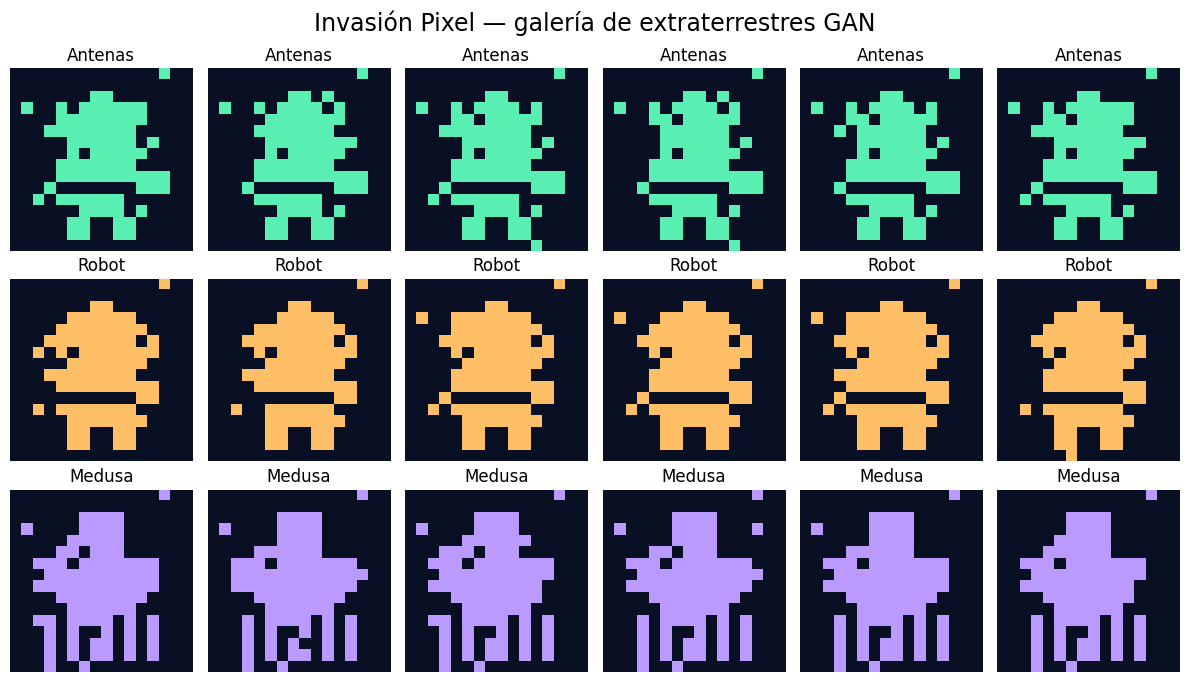

Imagen guardada: resultados_semana13/galeria_alienigenas_gan.png
Pesos guardados: resultados_semana13/generador_pixelgan.pth


In [13]:
import os
os.makedirs("resultados_semana13", exist_ok=True)

imagenes_exportadas = []
clases_exportadas = []
for nombre in NOMBRES:
    imagenes, clases = generar_alienes(nombre, cantidad=6, semilla=2026)
    imagenes_exportadas.extend(imagenes)
    clases_exportadas.extend(clases)

fig, axes = plt.subplots(3, 6, figsize=(12, 7))
for i, ax in enumerate(axes.ravel()):
    clase = int(clases_exportadas[i])
    ax.imshow((imagenes_exportadas[i] > 0.5), cmap=MAPAS[clase],
              vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(NOMBRES[clase])
    ax.axis("off")
fig.suptitle("Invasión Pixel — galería de extraterrestres GAN", fontsize=17)
fig.tight_layout()
archivo_png = "resultados_semana13/galeria_alienigenas_gan.png"
fig.savefig(archivo_png, dpi=180, bbox_inches="tight")
plt.show()

torch.save(generador.state_dict(), "resultados_semana13/generador_pixelgan.pth")
print("Imagen guardada:", archivo_png)
print("Pesos guardados: resultados_semana13/generador_pixelgan.pth")

## 14. Actividades para explorar y debatir

1. **Cambia las épocas:** entrena 40, 70 y 100 épocas. ¿Cómo cambia el dibujo? ¿Es posible que empeore al seguir entrenando?
2. **Elige otra familia:** cambia `FAMILIA_ELEGIDA` y la semilla. ¿La condición se respeta siempre?
3. **Busca el colapso de modos:** genera 120 criaturas y observa si aparecen diseños casi idénticos.
4. **Piensa en aumento de datos:** ¿qué pruebas realizarías para demostrar que estos dibujos mejorarían un clasificador de especies? No basta con que se vean atractivos.

### Resultados esperados y límites

Se espera ver una transición desde ruido hacia figuras tipo pixel-art, pero **no existe una garantía de calidad ni de diversidad** en cada ejecución. Aunque se guarden nuevas imágenes para ampliar el catálogo, no hemos realizado una evaluación *downstream* con un clasificador. Tampoco hemos implementado transferencia de estilo como Pix2Pix o CycleGAN; cambiar la paleta de visualización no es transferencia de estilo aprendida.

## 15. Guion breve para explicar el ejemplo en clase (aprox. 1 minuto)

«Hoy vamos a crear una fábrica de extraterrestres para un videojuego retro. Primero armamos un catálogo de referencia. Después entrenamos dos inteligencias artificiales al mismo tiempo. La primera, llamada generador, dibuja criaturas desde números aleatorios. La segunda, llamada discriminador, intenta descubrir si el dibujo viene del catálogo o lo hizo la primera red. Al competir muchas veces, el generador aprende a crear figuras parecidas a las del catálogo. Además, le decimos si queremos una criatura con antenas, un robot o una medusa. Finalmente, jugamos a reconocer cuáles son del catálogo y cuáles las generó la GAN. Lo importante es comprender que una IA generativa aprende patrones: no significa que comprenda qué es un extraterrestre, y debemos revisar tanto la calidad como la variedad de sus resultados».

### Conclusión

La práctica demuestra una **GAN condicional funcional** con un dataset sintético pequeño. Su aporte didáctico es hacer visibles las decisiones de G y D, la evolución del entrenamiento, el espacio latente y las limitaciones del realismo y la diversidad. Es una propuesta de laboratorio creativa, **no una afirmación de novedad científica absoluta**.

### Referencias esenciales

- Goodfellow, I., Pouget-Abadie, J., Mirza, M., et al. (2014). *Generative adversarial nets*. Advances in Neural Information Processing Systems, 27. https://arxiv.org/abs/1406.2661
- Mirza, M., & Osindero, S. (2014). *Conditional generative adversarial nets*. arXiv. https://arxiv.org/abs/1411.1784
- Radford, A., Metz, L., & Chintala, S. (2016). *Unsupervised representation learning with deep convolutional generative adversarial networks*. ICLR. https://arxiv.org/abs/1511.06434

*El diseño, el código de las figuras sintéticas y el desafío didáctico fueron preparados para este laboratorio.*